# MoBot: visual navigation and docking with an EKF and LQR (Track A)

A TurtleBot3 Burger in a MuJoCo room (three boxes, a sofa and a coffee table) has to find the charging dock marked with an ArUco tag and park in front of it.

**Pipeline:** camera + LiDAR + wheel encoders + gyro → **EKF** (odometry prediction, ArUco pose update) → planner (search / explore / approach / align / dock) → **LQR** line-tracking controller → wheels.

**Ground truth rule:** the robot code in `src/estimator.py`, `src/planner.py`, `src/control.py`, `src/marker.py`, `src/model.py` only sees sensor readings. The simulator's true pose (`src/judge.py`, `eval/`) is used **only** to score runs and draw plots.


In [ ]:
import os, shutil
if not os.path.exists("Mobile-Robot-docking"):
    !git clone -q https://github.com/anne-sharon/Mobile-Robot-docking.git
%cd Mobile-Robot-docking
!pip install -q mujoco opencv-python matplotlib scipy imageio-ffmpeg

# Pick an offscreen renderer: EGL on a GPU runtime, software OSMesa on a CPU runtime.
if shutil.which("nvidia-smi"):
    icd = "/usr/share/glvnd/egl_vendor.d/10_nvidia.json"
    if not os.path.exists(icd):
        os.makedirs(os.path.dirname(icd), exist_ok=True)
        with open(icd, "w") as f:
            f.write('{"file_format_version": "1.0.0", "ICD": {"library_path": "libEGL_nvidia.so.0"}}')
    os.environ["MUJOCO_GL"] = "egl"
else:
    !apt-get -qq update
    !apt-get -qq install -y --fix-missing libosmesa6-dev > /dev/null
    os.environ["MUJOCO_GL"] = "osmesa"
os.environ["PYOPENGL_PLATFORM"] = os.environ["MUJOCO_GL"]
print("renderer:", os.environ["MUJOCO_GL"])

/content/Mobile-Robot-docking
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
renderer: osmesa


## A. Model: controllability and observability
Unicycle model of the TurtleBot3, the linearised path-tracking error model used for the LQR, and the camera measurement model used by the EKF (all in `src/model.py`).

In [ ]:
from src.model import analysis, lqr, tracking_error_model
from src.control import Q_LQR, R_LQR
for k, v in analysis().items():
    print(f"{k:45s} rank {v}")
print()
for v in (0.05, 0.12, 0.20):
    K, poles = lqr(*tracking_error_model(v), Q_LQR, R_LQR)
    print(f"LQR at v = {v:.2f} m/s:  K = {K.round(2).ravel()}   closed-loop poles = {poles.real.round(2)}")

pose_error_controllability_rank(v_r=0.15)     rank 3
pose_error_controllability_rank(v_r=0.0)      rank 2
lateral_controllability_rank                  rank 2
pose_observability_rank_camera                rank 3
pose_observability_rank_odometry_only         rank 0

LQR at v = 0.05 m/s:  K = [20.   5.9]   closed-loop poles = [-0.17 -5.73]
LQR at v = 0.12 m/s:  K = [20.    6.13]   closed-loop poles = [-0.42 -5.71]
LQR at v = 0.20 m/s:  K = [20.    6.39]   closed-loop poles = [-0.7  -5.69]


## B. Sensing: camera calibration and measurement noise
1. Checkerboard calibration (Zhang's method) of the robot's camera → `models/camera_calibration.json` (used by the robot).
2. ArUco pose error against distance, from 400 known poses → camera bias correction and the EKF's measurement noise R (`models/camera_noise.json`). About 30 s.

calibration: 40 views, RMS reprojection error 0.059 px, focal length error 0.024 %


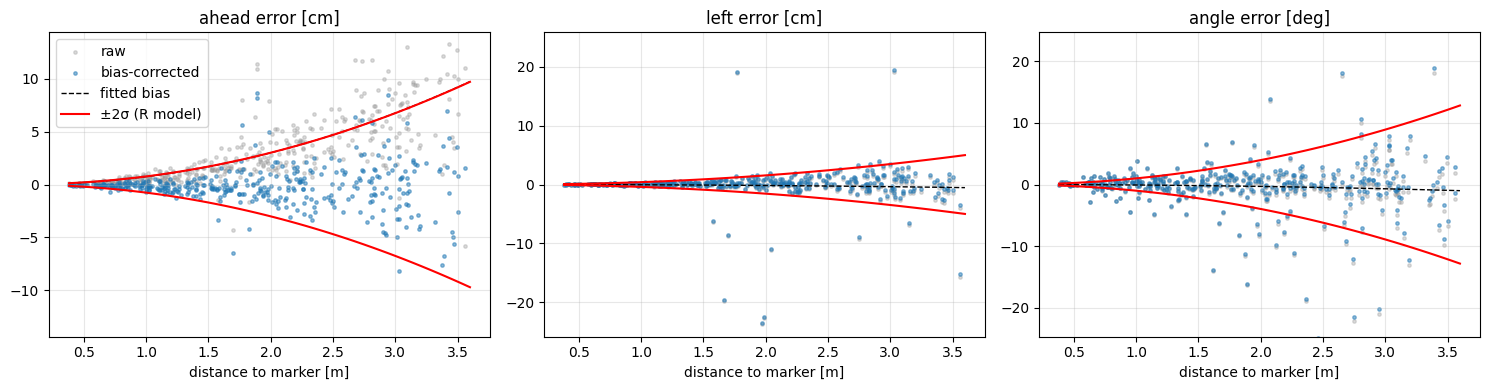

{
 "bias_c": {
  "ahead": 0.007515971314820138,
  "left": -0.0004076662829330023,
  "angle": -0.0013428725389469723
 },
 "ahead": {
  "a": 0.0001,
  "b": 0.0037405041482968045
 },
 "left": {
  "a": 0.0001,
  "b": 0.0019189496313831715
 },
 "angle": {
  "a": 0.0001,
  "b": 0.00864018499723147
 },
 "angle_outlier_rate": 0.04
}


In [ ]:
import json
from eval.calibrate_camera import calibrate
from eval.characterise_camera import characterise
cal = calibrate()
print(f"calibration: {cal['views_used']} views, RMS reprojection error {cal['rms_reprojection_px']:.3f} px, "
      f"focal length error {cal['focal_error_pct']:.3f} %")
noise = characterise()
print(json.dumps({k: noise[k] for k in ('bias_c', 'ahead', 'left', 'angle', 'angle_outlier_rate')}, indent=1))

## C + D. One docking run: path, EKF error and uncertainty
Left: robot path coloured by planner stage. Below: EKF error (estimate − truth) with its ±2σ band, and NEES (consistency).

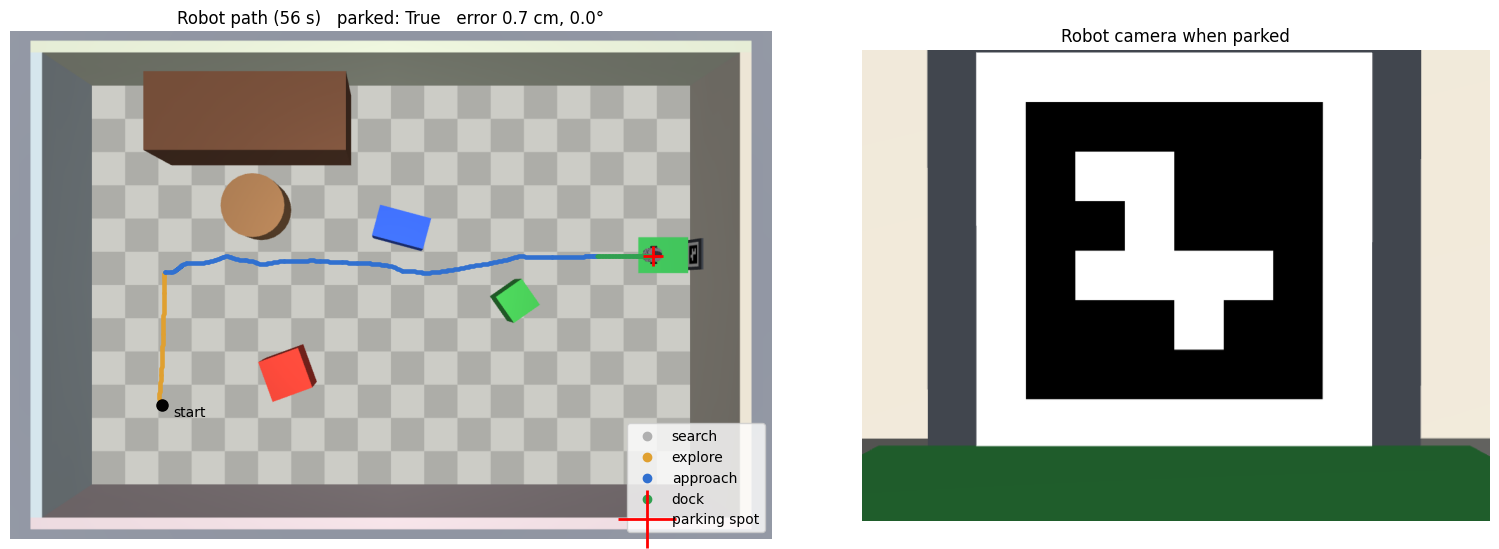

{'pos_m': 0.006661921354539783, 'heading_deg': 0.023483308548057424, 'parked': True}


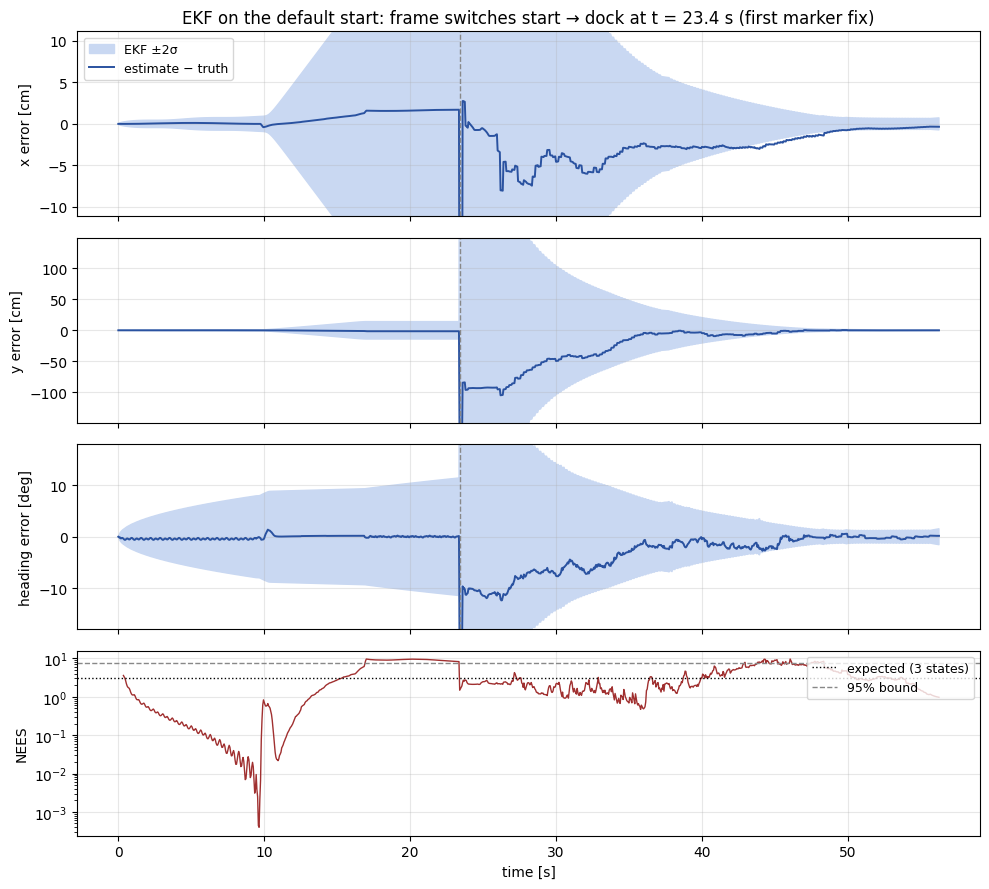

{'pos_m': 0.006661921354539783, 'heading_deg': 0.023483308548057424, 'parked': True, 'collisions': 0, 'mean_pose_err_m': 0.14584159334494723, 'mean_pose_err_dock_frame_m': 0.24345443507567602, 'mean_pose_err_near_dock_m': 0.011129519498865922, 'final_pose_err_m': 0.003451784840136082, 'mean_nees': 3.2931129314107657, 'time': 56.25000000002278, 'updates': 148, 'rejected': 2, 'reinits': 0}


In [ ]:
from eval.plot_episode import run_and_plot
from eval.plot_ekf import plot_error
print(run_and_plot())
print(plot_error())

## Video: nominal run
Overhead view (coloured = true path, white = EKF estimate with its 2σ ellipse), the robot's camera, and the estimation error with its ±2σ band.


In [ ]:
from IPython.display import Video, display
from eval.make_video import make_video
out, result = make_video("nominal")
print(result)
display(Video(out, embed=True, width=960))

{'pos_m': 0.006661921354539783, 'heading_deg': 0.023483308548057424, 'parked': True}


## Video: disturbed run
When the robot first comes within 1.5 m of the dock it is shoved sideways (the wheels slip, so odometry doesn't see it). Watch the error jump, the uncertainty grow, and the camera pull the estimate back.

In [ ]:
out, result = make_video("push")
print(result)
display(Video(out, embed=True, width=960))

{'pos_m': 0.006362529025374953, 'heading_deg': 0.2344599235352547, 'parked': True}


## E. Robustness study (optional, slow)
Repeated trials from 20 start poses under each condition: nominal, gyro noise + bias, camera pixel noise, push, occlusion, combined.

In [ ]:
from eval import run_batch
summary = run_batch.main(["nominal", "push", "occlusion"], n=5)

{'condition': 'nominal', 'runs': 5, 'runs_disturbed': 0, 'parked': 5, 'runs_with_collision': 0, 'park_err_cm_mean': np.float64(1.06), 'park_err_cm_worst': np.float64(1.84), 'heading_err_deg_mean': np.float64(0.49), 'heading_err_deg_worst': np.float64(1.22), 'time_s_mean': np.float64(44.63), 'est_err_near_dock_cm': np.float64(1.27), 'est_err_final_mm': np.float64(4.53), 'nees_mean': np.float64(3.05), 'rejected_per_run': np.float64(0.6), 'reinits_per_run': np.float64(0.0)}
{'condition': 'push', 'runs': 5, 'runs_disturbed': 5, 'parked': 5, 'runs_with_collision': 0, 'park_err_cm_mean': np.float64(1.02), 'park_err_cm_worst': np.float64(1.78), 'heading_err_deg_mean': np.float64(0.58), 'heading_err_deg_worst': np.float64(0.92), 'time_s_mean': np.float64(44.6), 'est_err_near_dock_cm': np.float64(1.25), 'est_err_final_mm': np.float64(3.58), 'nees_mean': np.float64(3.21), 'rejected_per_run': np.float64(4.0), 'reinits_per_run': np.float64(0.6)}
{'condition': 'occlusion', 'runs': 5, 'runs_disturbe

## Official score
`eval/run_episode.py`: the judge's ground truth is only used for scoring.

In [ ]:
from eval.run_episode import run_episode
print(run_episode())

{'pos_m': 0.006661921354539783, 'heading_deg': 0.023483308548057424, 'parked': True, 'collisions': 0, 'mean_pose_err_m': 0.14584159334494723, 'mean_pose_err_dock_frame_m': 0.24345443507567602, 'mean_pose_err_near_dock_m': 0.011129519498865922, 'final_pose_err_m': 0.003451784840136082, 'mean_nees': 3.2931129314107657}
